like/check :
$$f(x_j) = f(x_0 ,x_{f2(j)}) $$

or may be a function that calls itself, till it reaches a base case..see the laws...here the fuction g(j) make the recursion approach the base case, here 'x' may be a vector, list , tuple etc
$$f(x_j) = f(x_{g(j)}) $$

### Recursive Generalization Formula

The recursive definition for a function like the factorial $n!$ can be generalized using a piecewise equation:

$$
f(n) = 
\begin{cases} 
\text{Base Case:} & c & \text{if } n = 0 \\
\text{Recursive Step:} & g(n, f(n-1)) & \text{if } n > 0 
\end{cases}
$$

For example, the standard **Factorial** recursion is written as:

$$
n! = 
\begin{cases} 
1 & \text{if } n = 0 \\
n \times (n-1)! & \text{if } n > 0 
\end{cases}
$$


In [1]:
def list_sum(num_list):
    if len(num_list) == 1:
        return num_list[0]
    else:
        return num_list[0] + list_sum(num_list[1:])
print(list_sum([1,3,5,7,9]))

25


In [2]:
def facto(num):
    #if num == 0:
    if num <= 1:
        return 1
    else:
        return num * facto(num-1)
facto(3)

6

In [3]:
def factorial(n: int) -> int:
    """
    A recursive function to calculate the factorial of n.
    
    Base Case: if n is 0, return 1.
    Recursive Step: if n > 0, return n multiplied by the factorial of (n - 1).
    """
    # 1. Base Case
    if n == 0:
        return 1
    
    # 2. Recursive Step (Self-referential generalization)
    else:
        return n * factorial(n - 1)

# --- Execution ---
if __name__ == "__main__":
    test_number = 5
    result = factorial(test_number)
    
    print(f"The factorial of {test_number} is: {result}")


The factorial of 5 is: 120


Converting an Integer to a String in Any Base

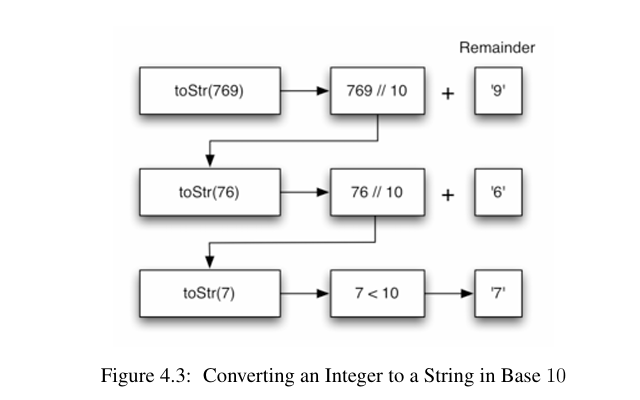

The algorithm works correctly because we make the recursive call first on
line 6, then we add the string representation of the remainder. If we reversed returning the
convertString lookup and returning the toStr call, the resulting string would be backward! But
by delaying the concatenation operation until after the recursive call has returned, we get the
result in the proper order. This should remind you of our discussion of stacks back in the
previous chapter.

In [4]:
#The code below shows the Python code that implements the algorithm outlined above for any
#base between 2 and 16.

def to_str(n, base):
    convert_string = "0123456789ABCDEF"
    if n < base:
        return convert_string[n]
    else:
        return to_str(n // base, base) + convert_string[n % base]

print(to_str(1453, 16))
print(to_str(13, 2))

5AD
1101


In [5]:
print(to_str(10, 2))

1010


In [6]:
#a function that takes a string as a parameter and returns a new string that is the reverse ofthe old string.
def revers_string(string):
    if len(string) == 1:
        return string
    else:
        #return string[0] + revers_string(string[1:])
        return revers_string(string[1:]) + string[0]
revers_string('abcdefgh')

'hgfedcba'

**so recursion is just a nice while loop mixed with stacking?...**

In [7]:
class Stack:
    def __init__(self):
        self.items = []
    def is_empty(self):
        return self.items == [] # returns true if empty
    def push(self, item):
        self.items.append(item)
    def pop(self):
        return self.items.pop()
        #if len(self.items) != 0:
         #   return self.items.pop()
        #else:
         #   return 'XXX'
    def peek(self):
        return self.items[len(self.items)-1]
    def size(self):
        return len(self.items)
    def head (self):
       return self.items[:5]
    def tail (self): # but tail does not show it in reverse order
       return self.items[-5:]
        
r_stack = Stack()
def to_str(n, base):
    r_stack = Stack()
    convert_string = "0123456789ABCDEF"
    while n > 0:
        if n < base:
            r_stack.push(convert_string[n])
        else:
            r_stack.push(convert_string[n % base])
        n = n // base
    res = ""
    while not r_stack.is_empty():
        res = res + str(r_stack.pop())
    return res


print(to_str(1453, 16))


5AD


**Visualising Recursion**\
See the online demo

In [8]:
def move_tower(height, from_pole, to_pole, with_pole):
    if height >= 1:
        move_tower(height- 1, from_pole, with_pole, to_pole) # move top plates to intermediate plate
        move_disk(from_pole, to_pole) # move the base disk
        move_tower(height- 1, with_pole, to_pole, from_pole) # moves those from the inetemediate to final plate 
def move_disk(fp,tp):
    print("moving disk from",fp,"to",tp )
move_tower(3, "A", "B", "C")

moving disk from A to B
moving disk from A to C
moving disk from B to C
moving disk from A to B
moving disk from C to A
moving disk from C to B
moving disk from A to B


now see the online interactive version of this book plus the pdf for some exercises

minimum number if coins

In [9]:
def make_change_2(coin_value_list, change, known_results):
    min_coins = change
    if change in coin_value_list:
        known_results[change] = 1
        return 1
    elif known_results[change] > 0:
        return known_results[change]
    else:
        for i in [c for c in coin_value_list if c <= change]:
            num_coins = 1 + make_change_2(coin_value_list, change - i, known_results)
            if num_coins < min_coins:
                min_coins = num_coins
            known_results[change] = min_coins
    return min_coins

print(make_change_2([1, 5, 10, 25], 63, [0] * 64))


6


In [10]:
def make_change_optimized(coin_list, change, known_results=None, coins_used=None):
    if known_results is None:
        known_results = [0] * (change + 1)
    if coins_used is None:
        coins_used = [0] * (change + 1)
        
    # Base Case
    if change in coin_list:
        known_results[change] = 1
        coins_used[change] = change
        return 1, coins_used
    
    # Check Memory
    elif known_results[change] > 0:
        return known_results[change], coins_used
    
    # Calculate and remember
    min_coins = change
    best_coin = 1
    
    for c in [coin for coin in coin_list if coin <= change]:
        # FIX: Unpack the tuple here so 'num_coins' gets just the number, not the whole pair!
        num_coins, _ = make_change_optimized(coin_list, change - c, known_results, coins_used)
        num_coins = 1 + num_coins
        
        if num_coins < min_coins:
            min_coins = num_coins
            best_coin = c  
            
    known_results[change] = min_coins
    coins_used[change] = best_coin 
    
    return min_coins, coins_used

# Helper function to print out the list of coins nicely
def print_coins(coins_used, change):
    coin_history = []
    while change > 0:
        this_coin = coins_used[change]
        coin_history.append(this_coin)
        change = change - this_coin
    print(f"Coins used: {coin_history}")

# --- RUNNING THE CODE ---
target_amount = 63
elbonia_coins = [1, 5, 10, 21, 25]

total_coins, tracker = make_change_optimized(elbonia_coins, target_amount)

print(f"Total number of coins: {total_coins}")
print_coins(tracker, target_amount)


Total number of coins: 3
Coins used: [21, 21, 21]


In [11]:
#this not a recursive function solutiuon 
def make_change_3(coin_value_list, change, min_coins):
   # 1. The Master Loop: Start at 0 cents and calculate every single amount up to 'change'
   for cents in range(change + 1):
      
      # 2. The Worst Case Scenario: Assume the worst-case setup is using all pennies.
      # (e.g., to make 11 cents, assume it takes 11 coins for now)
      coin_count = cents
      
      # 3. Test Every Coin: Look at every coin smaller than our current 'cents' amount
      for j in [c for c in coin_value_list if c <= cents]:
          
            # 4. The Magic Lookup: Look at our cheat sheet ('min_coins') for the leftover amount.
            # "If I use coin 'j', how many coins did it take to make (cents - j) earlier?"
            # Add 1 to that number (for the coin we are holding). 
            # Is that smaller than our current record?
            if min_coins[cents - j] + 1 < coin_count:
               
               # 5. New Record: If it's fewer coins, update our best count for this amount.
               coin_count = min_coins[cents - j] + 1
               
      # 6. Save to Cheat Sheet: Lock in the absolute best answer for this 'cents' amount.
      min_coins[cents] = coin_count
      
   # 7. Final Answer: Grab the exact answer we calculated for our target change amount.
   return min_coins[change]


# 1. Define the coins we want to use (Lower Elbonia setup)
elbonia_coins = [1, 5, 10, 21, 25]

# 2. Set the target amount
target_change = 63

# 3. Create the "min_coins" parameter: a list of 64 zeros 
# This creates: [0, 0, 0, 0, ... up to 64 zeros]
blank_cheat_sheet = [0] * (target_change + 1)

# 4. Run the function!
result = make_change_3(elbonia_coins, target_change, blank_cheat_sheet)

print(f"Minimum coins needed: {result}")
# Output: Minimum coins needed: 3


Minimum coins needed: 3


In [12]:
def make_change_4(coin_value_list, change, min_coins, coins_used):
    """
    Builds the cheat sheet from 0 cents up to the target change amount.
    It tracks BOTH the minimum number of coins AND the best coin used at each step.
    """
    # Loop through every single amount from 0 cents up to our target change
    for cents in range(change + 1):
        # Worst-case scenario: Assume we have to use all pennies 
        # (e.g., 11 cents would take 11 coins)
        coin_count = cents
        
        # Default to using a penny until we find a better combination
        new_coin = 1
        
        # Test every coin option that is smaller than or equal to the current 'cents'
        for j in [c for c in coin_value_list if c <= cents]:
            
            # The Magic Lookup: Look up the best answer for the remaining amount (cents - j).
            # Add 1 to represent the coin we are currently holding in our hand.
            if min_coins[cents - j] + 1 < coin_count:
                # If this option uses fewer total coins, update our record!
                coin_count = min_coins[cents - j] + 1
                # Remember this specific coin as the winner for this amount
                new_coin = j
                
        # Lock in the final best coin count for this amount into our cheat sheet
        min_coins[cents] = coin_count
        
        # Drop a breadcrumb: Save the winning coin used for this amount
        coins_used[cents] = new_coin
        
    # Return the final calculated minimum number of coins for our target change
    return min_coins[change]


def print_coins(coins_used, change):
    """
    Follows the breadcrumb trail backward from the target change amount
    to print out every coin that was actually used.
    """
    coin = change
    
    # Keep walking backward until we reach 0 cents
    while coin > 0:
        # Look up the winning coin for the current remaining amount
        this_coin = coins_used[coin]
        
        # Print the coin out on the screen
        print(this_coin, end=" ")
        
        # Deduct the coin value to jump backward to the next leftover amount
        coin = coin - this_coin
    print()


def main():
    # 1. Setup the inputs
    amnt = 63                          # The target change we want to make
    clist = [1, 5, 10, 21, 25]         # The available coin values (Lower Elbonia setup)
    
    # 2. Setup the empty lists (sized to amnt + 1 so index 63 is valid)
    coins_used = [0] * (amnt + 1)      # Will store the breadcrumb trail of best coins
    coin_count = [0] * (amnt + 1)      # Will act as our main lookup cheat sheet

    # 3. Run the solver and print the results
    print(
       "Making change for {} requires the following {} coins: ".format(
             amnt, make_change_4(clist, amnt, coin_count, coins_used)
       ),
       end="",
    )
    
    # Trace the breadcrumbs backward to print the actual coins used (e.g., 21 21 21)
    print_coins(coins_used, amnt)
    
    # 4. Show the raw breadcrumb array for context
    print("\nThe raw coins_used list is as follows:")
    print(coins_used)


# This line actually triggers the program to start running
main()


Making change for 63 requires the following 3 coins: 21 21 21 

The raw coins_used list is as follows:
[1, 1, 1, 1, 1, 5, 1, 1, 1, 1, 10, 1, 1, 1, 1, 5, 1, 1, 1, 1, 10, 21, 1, 1, 1, 25, 1, 1, 1, 1, 5, 10, 1, 1, 1, 10, 1, 1, 1, 1, 5, 10, 21, 1, 1, 10, 21, 1, 1, 1, 25, 1, 10, 1, 1, 5, 10, 1, 1, 1, 10, 1, 10, 21]


In [5]:

# Output: Minimum coins needed: 3


Minimum coins needed: 3
